# **Project: Fraud Detection using Logistic Regression**

the objective of this project was to build a machine learning classification model to identify whether a financial transaction id fradulent or not.

The target variable was is_fraud, where:

0 = Not Fraud

1 = Fraud

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("/content/credit_card_fraud_10k.csv")

In [3]:
df.head()

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [4]:
df.tail()

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
9995,9996,350.91,22,Food,0,0,99,4,37,0
9996,9997,410.04,5,Clothing,0,0,70,3,25,0
9997,9998,527.75,21,Electronics,0,0,44,2,45,0
9998,9999,91.20,2,Electronics,0,0,38,0,37,0
9999,10000,44.06,2,Clothing,0,0,38,0,66,0


In [5]:
df.isnull().sum()

,0
transaction_id,0
amount,0
transaction_hour,0
merchant_category,0
foreign_transaction,0
location_mismatch,0
device_trust_score,0
velocity_last_24h,0
cardholder_age,0
is_fraud,0


In [6]:
df.sample(5)

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
697,698,156.68,6,Food,0,0,38,1,59,0
1344,1345,244.36,2,Electronics,0,1,72,2,51,0
169,170,160.88,0,Food,0,0,89,2,49,0
1550,1551,544.36,20,Food,0,1,39,2,60,0
3164,3165,10.41,3,Clothing,0,0,66,0,42,0


In [7]:
df.shape

(10000, 10)

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

,0
transaction_id,int64
amount,float64
transaction_hour,int64
merchant_category,object
foreign_transaction,int64
location_mismatch,int64
device_trust_score,int64
velocity_last_24h,int64
cardholder_age,int64
is_fraud,int64


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  object 
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), object(1)
memory usage: 781.4+ KB


In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
transaction_id,10000.0,5000.500000,2886.895680,1.0,2500.750,5000.500,7500.25,10000.00
amount,10000.0,175.949849,175.392827,0.0,50.905,122.095,242.48,1471.04
transaction_hour,10000.0,11.593300,6.922708,0.0,6.000,12.000,18.00,23.00
foreign_transaction,10000.0,0.097800,0.297059,0.0,0.000,0.000,0.00,1.00
location_mismatch,10000.0,0.085700,0.279935,0.0,0.000,0.000,0.00,1.00
device_trust_score,10000.0,61.798900,21.487053,25.0,43.000,62.000,80.00,99.00
velocity_last_24h,10000.0,2.008900,1.432559,0.0,1.000,2.000,3.00,9.00
cardholder_age,10000.0,43.468700,14.979147,18.0,30.000,44.000,56.00,69.00
is_fraud,10000.0,0.015100,0.121957,0.0,0.000,0.000,0.00,1.00


# **Dataset**

I worked with a synthetic transaction dataset containing 10,000 records.

The dataset contained features such as:

Transaction amount

Transaction hour

Merchant category

Foreign transaction

Location mismatch

Device trust score

Transaction velocity
Cardholder age

The target variable was **is_fraud**.

In [12]:
df.describe(include='object')

,merchant_category
count,10000
unique,5
top,Food
freq,2093


In [13]:
num_feat=['transaction_hour', 'device_trust_score', 'velocity_last_24h', 'cardholder_age']

df.describe()[num_feat].T

,count,mean,std,min,25%,50%,75%,max
transaction_hour,10000.0,11.5933,6.922708,0.0,6.0,12.0,18.0,23.0
device_trust_score,10000.0,61.7989,21.487053,25.0,43.0,62.0,80.0,99.0
velocity_last_24h,10000.0,2.0089,1.432559,0.0,1.0,2.0,3.0,9.0
cardholder_age,10000.0,43.4687,14.979147,18.0,30.0,44.0,56.0,69.0


In [14]:
df.columns.tolist()

['transaction_id',
 'amount',
 'transaction_hour',
 'merchant_category',
 'foreign_transaction',
 'location_mismatch',
 'device_trust_score',
 'velocity_last_24h',
 'cardholder_age',
 'is_fraud']

In [15]:
df['merchant_category'].unique()

array(['Electronics', 'Travel', 'Grocery', 'Food', 'Clothing'],
      dtype=object)

In [16]:
df['is_fraud'].unique()

array([0, 1])

In [17]:
cat_feature = ['merchant_category', 'foreign_transaction', 'location_mismatch', 'is_fraud']

for col in cat_feature:
  print(f"Unique values are {df[col].unique()}")

Unique values are ['Electronics' 'Travel' 'Grocery' 'Food' 'Clothing']
Unique values are [0 1]
Unique values are [0 1]
Unique values are [0 1]


## **Performing Detailed EDA**

**Data Understanding and EDA**

First, I performed exploratory data analysis to understand:

Dataset shape and data types

Missing values

Duplicate records

Unique values

Numerical distributions

Categorical variables

Target class distribution

**The dataset was highly imbalanced:**

Not Fraud = 98.49%

Fraud = 1.51%

Therefore, accuracy alone was not sufficient for evaluating the model.

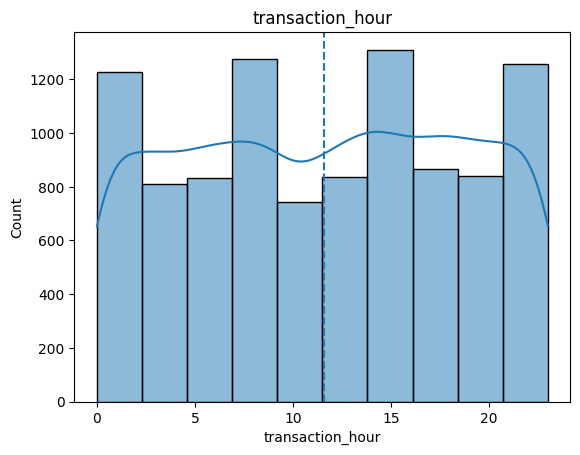

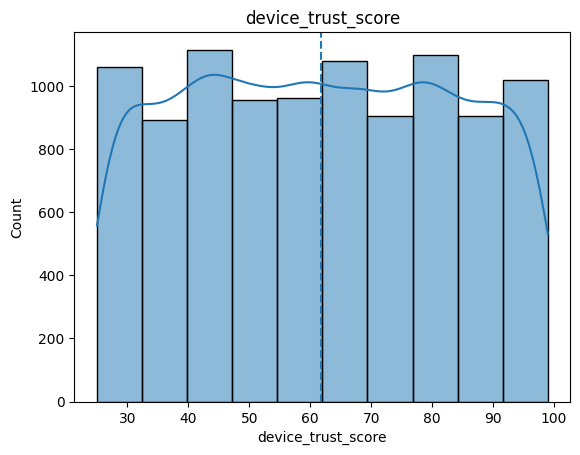

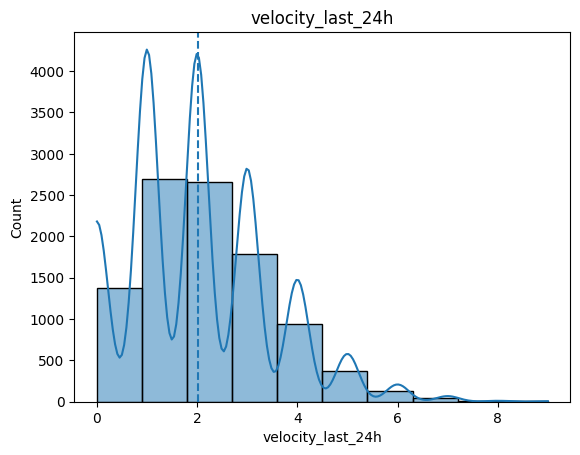

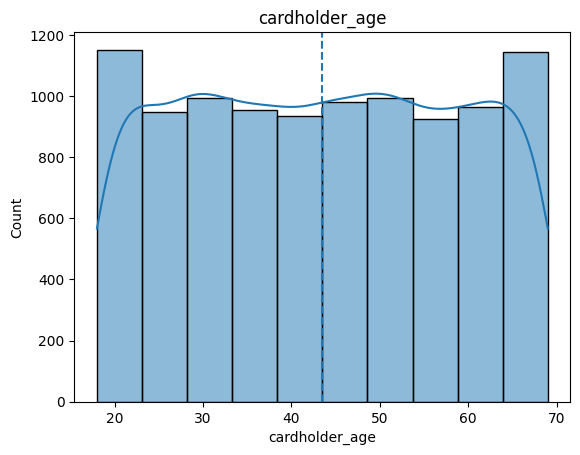

In [18]:
for col in num_feat:
    sns.histplot(df[col], kde=True, bins=10)
    plt.axvline(df[col].mean(), linestyle='--')
    plt.title(col)
    plt.show()

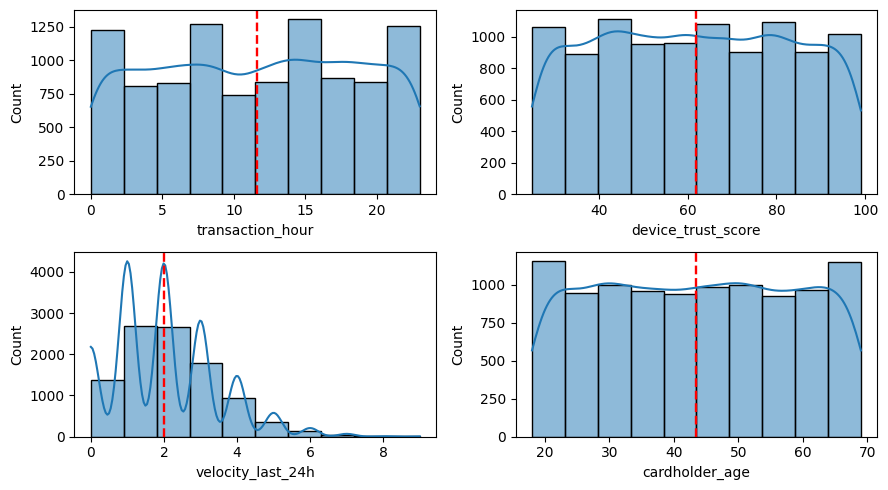

In [19]:
# observing the balanceness of the categorical features
fig,ax=plt.subplots(2,2,figsize=(9,5))
ax=ax.flatten()

for i,col in enumerate(num_feat):
    sns.histplot(x=df[col],kde=True,bins=10,ax=ax[i])
    ax[i].axvline(df[col].mean(),linestyle='--',color='red',linewidth=1.7)
plt.tight_layout()
plt.show()

None of them follows the any particular distribution .

most of them are domed shape distribution .

Velocity columns is heavily right skewed.

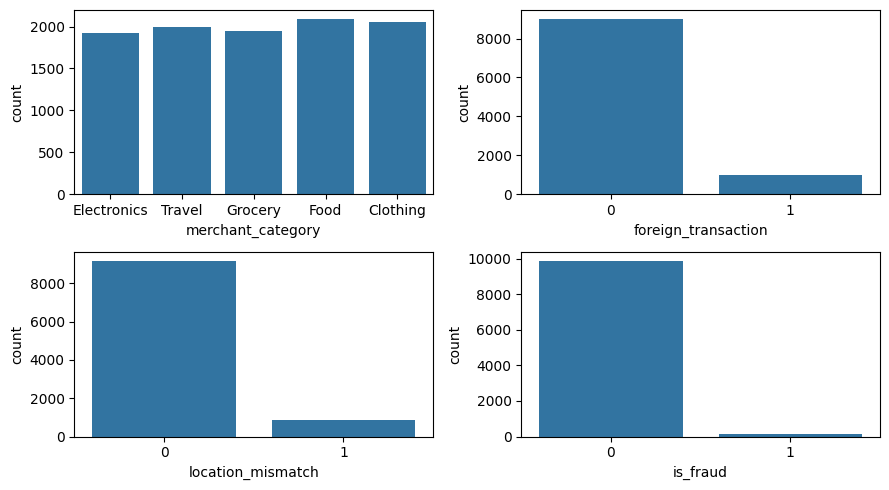

In [20]:
# observing the balanceness of the categorical features

fig,ax=plt.subplots(2,2,figsize=(9,5))
ax=ax.flatten()

for i,col in enumerate(cat_feature):
    sns.countplot(x=df[col],ax=ax[i])
plt.tight_layout()
plt.show()

Easily it can get observed that fraud transaction are limited .

Even Mismatch are also limited.

There is no dominance can get observed within mechant category .

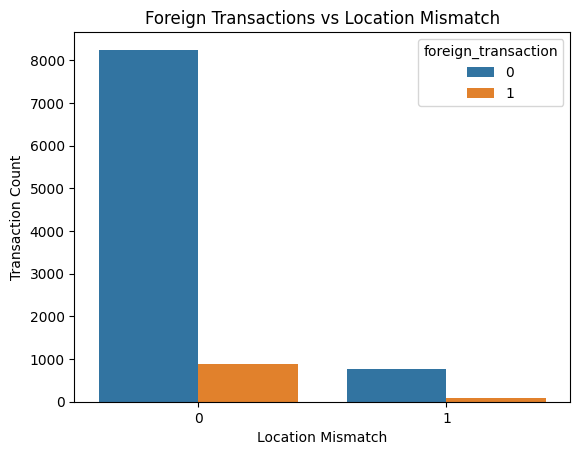

In [21]:
# Observing is location mismatch , foreign transaction leads to have high chances of fraud transaction .

sns.countplot(
    data=df,
    x='location_mismatch',
    hue='foreign_transaction'
)

plt.title('Foreign Transactions vs Location Mismatch')
plt.xlabel('Location Mismatch')
plt.ylabel('Transaction Count')
plt.show()

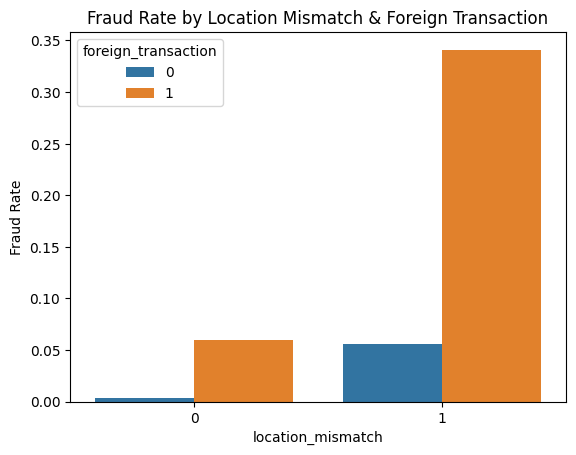

In [22]:
fraud_rate = (
    df.groupby(['location_mismatch', 'foreign_transaction'])['is_fraud']
      .mean()
      .reset_index()
)

sns.barplot(
    data=fraud_rate,
    x='location_mismatch',
    y='is_fraud',
    hue='foreign_transaction'
)

plt.ylabel('Fraud Rate')
plt.title('Fraud Rate by Location Mismatch & Foreign Transaction')
plt.show()


So there will be high chances of Fraud transaction if the location is mismatched & transaction is from foreign.

In [23]:
df.head()

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [24]:
import plotly.express as px
px.pie(data_frame=df, names=df['is_fraud'],height=400 ,width=500).show()

In [25]:
df.head(20)

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0
5,6,30.53,13,Clothing,0,0,90,2,46,0
6,7,10.77,18,Travel,0,0,48,1,28,0
7,8,362.02,13,Electronics,0,0,68,1,40,0
8,9,165.43,8,Grocery,0,0,80,0,21,0
9,10,221.63,5,Grocery,0,0,59,1,34,0


# **Data Preprocessing**

I removed transaction_id because it was only an identifier and did not provide meaningful predictive information.

I separated the dataset into:

X = Features

y = Target

Then I performed an 80:20 train-test split using stratification so that the class distribution was preserved.

The categorical merchant_category feature was converted into numerical features using One-Hot Encoding.

In [26]:
df = pd.get_dummies(df, columns=['merchant_category'], dtype=int)

In [27]:
x = df.drop(columns=['transaction_id', 'is_fraud'])
y = df['is_fraud']

In [28]:
df.head()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud,merchant_category_Clothing,merchant_category_Electronics,merchant_category_Food,merchant_category_Grocery,merchant_category_Travel
0,1,84.47,22,0,0,66,3,40,0,0,1,0,0,0
1,2,541.82,3,1,0,87,1,64,0,0,0,0,0,1
2,3,237.01,17,0,0,49,1,61,0,0,0,0,1,0
3,4,164.33,4,0,1,72,3,34,0,0,0,0,1,0
4,5,30.53,15,0,0,79,0,44,0,0,0,1,0,0


In [29]:
x

,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,merchant_category_Clothing,merchant_category_Electronics,merchant_category_Food,merchant_category_Grocery,merchant_category_Travel
0,84.47,22,0,0,66,3,40,0,1,0,0,0
1,541.82,3,1,0,87,1,64,0,0,0,0,1
2,237.01,17,0,0,49,1,61,0,0,0,1,0
3,164.33,4,0,1,72,3,34,0,0,0,1,0
4,30.53,15,0,0,79,0,44,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,350.91,22,0,0,99,4,37,0,0,1,0,0
9996,410.04,5,0,0,70,3,25,1,0,0,0,0
9997,527.75,21,0,0,44,2,45,0,1,0,0,0
9998,91.20,2,0,0,38,0,37,0,1,0,0,0


In [30]:
y

,is_fraud
0,0
1,0
2,0
3,0
4,0
...,...
9995,0
9996,0
9997,0
9998,0


In [31]:
x.value_counts().sum()

np.int64(10000)

In [32]:
y.value_counts()

,count
is_fraud,
0,9849
1,151


In [33]:
from sklearn.model_selection import train_test_split

In [34]:
x_train, x_test, y_train, y_test = train_test_split(x, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

In [35]:
x_train.dtypes

,0
amount,float64
transaction_hour,int64
foreign_transaction,int64
location_mismatch,int64
device_trust_score,int64
velocity_last_24h,int64
cardholder_age,int64
merchant_category_Clothing,int64
merchant_category_Electronics,int64
merchant_category_Food,int64


In [36]:
print(x_train.shape)
print(y_train.shape)

(8000, 12)
(8000,)


In [37]:
print(x_train.columns)
print(x_test.columns)

Index(['amount', 'transaction_hour', 'foreign_transaction',
       'location_mismatch', 'device_trust_score', 'velocity_last_24h',
       'cardholder_age', 'merchant_category_Clothing',
       'merchant_category_Electronics', 'merchant_category_Food',
       'merchant_category_Grocery', 'merchant_category_Travel'],
      dtype='object')
Index(['amount', 'transaction_hour', 'foreign_transaction',
       'location_mismatch', 'device_trust_score', 'velocity_last_24h',
       'cardholder_age', 'merchant_category_Clothing',
       'merchant_category_Electronics', 'merchant_category_Food',
       'merchant_category_Grocery', 'merchant_category_Travel'],
      dtype='object')


In [38]:
y_train.value_counts()

,count
is_fraud,
0,7879
1,121


## **Applay Scaling**

# **Feature Scaling**

I used StandardScaler to standardize the numerical feature values.

I used:

scaler.fit_transform(x_train)

on training data and:

scaler.transform(x_test)

on test data.

This prevents information from the test set from influencing the scaling process.

In [39]:
from sklearn.preprocessing import StandardScaler

In [40]:
scaler = StandardScaler()

In [41]:
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [42]:
print(x_train_scaled.shape)
print(x_test_scaled.shape)

(8000, 12)
(2000, 12)


In [43]:
print(x_test_scaled.shape)

(2000, 12)


## **applay SMOAT**

# **Handling Class Imbalance**

Because the fraud class was highly underrepresented, I used **SMOTE — Synthetic Minority Oversampling Technique**.

SMOTE generated synthetic minority-class samples on the training data.

Importantly, I applied SMOTE only to the training data, not to the test data, to avoid data leakage.

In [44]:
from imblearn.over_sampling import SMOTE

In [45]:
smote = SMOTE(random_state=42)

x_train_resampled, y_train_resampled = smote.fit_resample(
    x_train_scaled,
    y_train
)

In [46]:
y_train.value_counts()

,count
is_fraud,
0,7879
1,121


In [47]:
y_train_resampled.value_counts()

,count
is_fraud,
0,7879
1,7879


# **Model Training**

I trained a **Logistic Regression model** using the processed and balanced training data.

Logistic Regression was used because this was a binary classification problem.

The model learned relationships between the transaction features and the probability of fraud.

In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
lr = LogisticRegression(random_state=42)

print(lr)

LogisticRegression(random_state=42)


In [50]:
lr.fit(x_train_resampled, y_train_resampled)

LogisticRegression(random_state=42)

In [51]:
y_pred = lr.predict(x_test_scaled)

In [52]:
print(y_pred[:50])

[0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [53]:
print(pd.Series(y_pred).value_counts())

0    1904
1      96
Name: count, dtype: int64


In [54]:
print(y_test.value_counts())

is_fraud
0    1970
1      30
Name: count, dtype: int64


## **Confusion Matrix**

In [55]:
from sklearn.metrics import confusion_matrix

In [56]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1902   68]
 [   2   28]]


In [57]:
print("TN:", cm[0, 0])
print("FP:", cm[0, 1])
print("FN:", cm[1, 0])
print("TP:", cm[1, 1])

TN: 1902
FP: 68
FN: 2
TP: 28


In [58]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve)

In [59]:
accuracy_score = accuracy_score(y_test, y_pred)
precision_score = precision_score(y_test, y_pred)
recall_score = recall_score(y_test, y_pred)
f1_score = f1_score(y_test, y_pred)
roc_auc_score = roc_auc_score(y_test, y_pred)
average_precision_score = average_precision_score(y_test, y_pred)
roc_curve = roc_curve(y_test, y_pred)
precision_recall_curve = precision_recall_curve(y_test, y_pred)


In [60]:

print("Accuracy: ", accuracy_score)
print("Precision: ", precision_score)
print("Recall: ", recall_score)
print("F1 Score: ", f1_score)
print("ROC AUC Score: ", roc_auc_score)
print("Average Precision Score: ", average_precision_score)


Accuracy:  0.965
Precision:  0.2916666666666667
Recall:  0.9333333333333333
F1 Score:  0.4444444444444444
ROC AUC Score:  0.9494077834179357
Average Precision Score:  0.27322222222222226


In [61]:
print(f"Accuracy : {accuracy_score*100:.2f}%")
print(f"Precision : {precision_score*100:.2f}%")
print(f"Recall : {recall_score*100:.2f}%")
print(f"F1 Score : {f1_score*100:.2f}%")
print(f"ROC AUC Score : {roc_auc_score*100:.2f}%")
print(f"Average Precision Score: {average_precision_score*100:.2f}%")

Accuracy : 96.50%
Precision : 29.17%
Recall : 93.33%
F1 Score : 44.44%
ROC AUC Score : 94.94%
Average Precision Score: 27.32%


In [62]:
y_prob = lr.predict_proba(x_test_scaled)[:, 1]

In [63]:
y_prob

array([3.12383331e-04, 1.47872959e-04, 1.92515975e-07, ...,
       6.17017368e-05, 1.53714978e-05, 1.35083251e-04])

In [64]:
threshold = 0.40

In [65]:
y_pred_new = (y_prob >= threshold).astype(int)

In [66]:
y_pred_new

array([0, 0, 0, ..., 0, 0, 0])

In [67]:
from sklearn.metrics import (accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             roc_auc_score,
                             average_precision_score)

In [68]:
y_prob = lr.predict_proba(x_test_scaled)[:, 1]
threshold = 0.40
y_pred_new = (y_prob >= threshold).astype(int)


In [69]:
accuracy = accuracy_score(y_test, y_pred_new)
precision = precision_score(y_test, y_pred_new)
recall = recall_score(y_test, y_pred_new)
f1 = f1_score(y_test, y_pred_new)

roc_auc = roc_auc_score(y_test, y_prob)
average_precision = average_precision_score(y_test, y_prob)


In [70]:
print(f"Threshold          : {threshold}")
print(f"Accuracy           : {accuracy * 100:.2f}%")
print(f"Precision          : {precision * 100:.2f}%")
print(f"Recall             : {recall * 100:.2f}%")
print(f"F1 Score           : {f1 * 100:.2f}%")
print(f"ROC-AUC            : {roc_auc * 100:.2f}%")
print(f"Average Precision  : {average_precision * 100:.2f}%")

Threshold          : 0.4
Accuracy           : 96.20%
Precision          : 27.88%
Recall             : 96.67%
F1 Score           : 43.28%
ROC-AUC            : 99.33%
Average Precision  : 75.10%


# **Threshold Tuning**

The default threshold of Logistic Regression is generally 0.5.

I tested multiple thresholds:

0.1, 0.2, 0.3, 0.4, 0.5,
0.6, 0.7, 0.8, 0.9

I compared Precision, Recall and F1-score at different thresholds.

At threshold 0.9:

**Precision = 45.61%**

**Recall = 86.67%**

**F1-score = 59.77%**

Among the thresholds tested, 0.9 produced the highest F1-score.

The threshold was therefore selected for this experiment based on the balance between precision and recall.

In [71]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.2%} | "
        f"Recall: {recall:.2%} | "
        f"F1: {f1:.2%}"
    )

Threshold: 0.1 | Precision: 17.96% | Recall: 100.00% | F1: 30.46%
Threshold: 0.2 | Precision: 22.22% | Recall: 100.00% | F1: 36.36%
Threshold: 0.3 | Precision: 23.77% | Recall: 96.67% | F1: 38.16%
Threshold: 0.4 | Precision: 27.88% | Recall: 96.67% | F1: 43.28%
Threshold: 0.5 | Precision: 29.17% | Recall: 93.33% | F1: 44.44%
Threshold: 0.6 | Precision: 32.56% | Recall: 93.33% | F1: 48.28%
Threshold: 0.7 | Precision: 35.44% | Recall: 93.33% | F1: 51.38%
Threshold: 0.8 | Precision: 40.58% | Recall: 93.33% | F1: 56.57%
Threshold: 0.9 | Precision: 45.61% | Recall: 86.67% | F1: 59.77%


In [72]:
from sklearn.metrics import confusion_matrix
threshold = 0.9
y_pred_09 = (y_prob >= threshold).astype(int)
cm_09 = confusion_matrix(y_test, y_pred)
print(cm_09)

[[1902   68]
 [   2   28]]


In [73]:
print("0.5 predictions:",(y_prob >= 0.5).sum())
print("0.9 predictions:",(y_prob >= 0.9).sum())

0.5 predictions: 96
0.9 predictions: 57


# **Confusion Matrix**

At threshold 0.9, the confusion matrix was:

                 Predicted
                 0       1
Actual  0      1939    |    31

Actual  1        4     |    26

Therefore:

**TN = 1939**

**FP = 31**

**FN = 4**

**TP = 26**

The model correctly identified 26 fraudulent transactions and missed 4 fraudulent transactions.

In [74]:
from sklearn.metrics import confusion_matrix

# Threshold 0.5
y_pred_05 = (y_prob >= 0.5).astype(int)
cm_05 = confusion_matrix(y_test, y_pred_05)

# Threshold 0.9
y_pred_09 = (y_prob >= 0.9).astype(int)
cm_09 = confusion_matrix(y_test, y_pred_09)

print("Threshold 0.5:")
print(cm_05)

print("\nThreshold 0.9:")
print(cm_09)

Threshold 0.5:
[[1902   68]
 [   2   28]]

Threshold 0.9:
[[1939   31]
 [   4   26]]


In [75]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Threshold 0.5
y_pred_05 = (y_prob >= 0.5).astype(int)

precision_05 = precision_score(y_test, y_pred_05)
recall_05 = recall_score(y_test, y_pred_05)
f1_05 = f1_score(y_test, y_pred_05)


# Threshold 0.9
y_pred_09 = (y_prob >= 0.9).astype(int)

precision_09 = precision_score(y_test, y_pred_09)
recall_09 = recall_score(y_test, y_pred_09)
f1_09 = f1_score(y_test, y_pred_09)


print("Threshold 0.5")
print("Precision:", precision_05)
print("Recall:", recall_05)
print("F1 Score:", f1_05)

print("\nThreshold 0.9")
print("Precision:", precision_09)
print("Recall:", recall_09)
print("F1 Score:", f1_09)

Threshold 0.5
Precision: 0.2916666666666667
Recall: 0.9333333333333333
F1 Score: 0.4444444444444444

Threshold 0.9
Precision: 0.45614035087719296
Recall: 0.8666666666666667
F1 Score: 0.5977011494252874


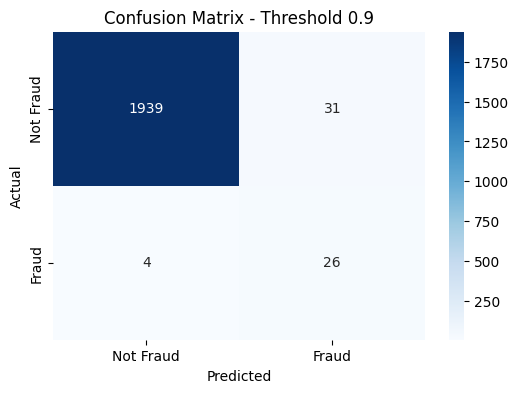

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Final threshold for this visualization
threshold = 0.9

y_pred_final = (y_prob >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Fraud', 'Fraud'],
    yticklabels=['Not Fraud', 'Fraud']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Threshold 0.9')

plt.show()

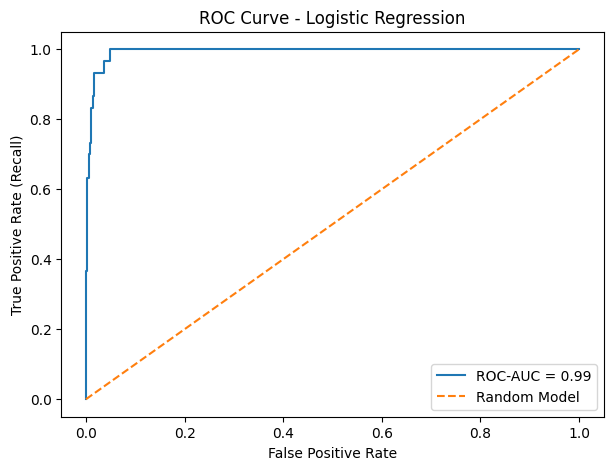

In [77]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob)

# Plot
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'ROC-AUC = {roc_auc:.2f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Model'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.show()

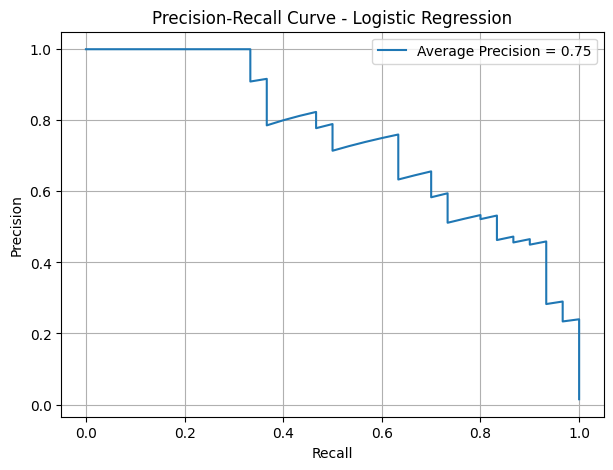

In [78]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Precision-Recall values
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob
)

# Average Precision
pr_auc = average_precision_score(y_test, y_prob)

# Plot
plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f'Average Precision = {pr_auc:.2f}'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Logistic Regression')
plt.legend()
plt.grid()

plt.show()

In [79]:
# Final threshold
final_threshold = 0.9

# Final predictions
y_pred_final = (y_prob >= final_threshold).astype(int)

print("Final Threshold:", final_threshold)

Final Threshold: 0.9


# **Final Model Evaluation**

The final evaluation results were:

**Metric	Score**

Accuracy	98.25%

Precision	45.61%

Recall	86.67%

F1-score	59.77%

ROC-AUC	99.33%

Average Precision	75.10%

Because the dataset was highly imbalanced, I did not rely on accuracy alone. I considered Precision, Recall, F1-score, ROC-AUC and Average Precision.

In [80]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Final threshold
final_threshold = 0.9

# Final predictions
y_pred_final = (y_prob >= final_threshold).astype(int)

# Metrics
accuracy = accuracy_score(y_test, y_pred_final)
precision = precision_score(y_test, y_pred_final)
recall = recall_score(y_test, y_pred_final)
f1 = f1_score(y_test, y_pred_final)

# Probability-based metrics
roc_auc = roc_auc_score(y_test, y_prob)
average_precision = average_precision_score(y_test, y_prob)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_final)

print("========== FINAL MODEL EVALUATION ==========")

print(f"Threshold           : {final_threshold}")
print(f"Accuracy            : {accuracy:.2%}")
print(f"Precision           : {precision:.2%}")
print(f"Recall              : {recall:.2%}")
print(f"F1 Score            : {f1:.2%}")
print(f"ROC-AUC             : {roc_auc:.2%}")
print(f"Average Precision   : {average_precision:.2%}")

print("\nConfusion Matrix:")
print(cm)

========== FINAL MODEL EVALUATION ==========
Threshold           : 0.9
Accuracy            : 98.25%
Precision           : 45.61%
Recall              : 86.67%
F1 Score            : 59.77%
ROC-AUC             : 99.33%
Average Precision   : 75.10%

Confusion Matrix:
[[1939   31]
 [   4   26]]


In [81]:
import joblib

# Save trained Logistic Regression model
joblib.dump(lr, "logistic_regression_lr.pkl")

# Save scaler
joblib.dump(scaler, "scaler.pkl")

print("lr and scaler saved successfully!")

lr and scaler saved successfully!


**New Transaction Prediction**

Finally, I loaded the saved model and scaler and tested a new transaction.

The model returned:

**Fraud Probability = 1.0**

**Prediction = 1**

**Result = FRAUD**

This demonstrated how the trained model can be used for predicting new transactions.

In [84]:
import pandas as pd
import joblib

# load saved model and scaler
loaded_lr = joblib.load("logistic_regression_lr.pkl")
loaded_scaler = joblib.load("scaler.pkl")

# new transaction

new_transaction = pd.DataFrame({
    'amount': [5000],
    'transaction_hour': [2],
    'foreign_transaction': [1],
    'location_mismatch': [1],
    'device_trust_score': [20],
    'velocity_last_24h': [8],
    'cardholder_age': [30],
    'merchant_category_Clothing': [0],
    'merchant_category_Electronics': [0],
    'merchant_category_Food': [0],
    'merchant_category_Grocery': [0],
    'merchant_category_Travel': [1]
})

# Scale the new transaction
new_transaction_scaled = loaded_scaler.transform(new_transaction)

# Fraud probability
fraud_probability = loaded_lr.predict_proba(new_transaction_scaled)[0, 1]

# Final prediction using threshold 0.9
final_prediction = int(fraud_probability >= 0.9)

print("Fraud Probability:", fraud_probability)
print("Prediction:", final_prediction)

if final_prediction == 1:
    print("Result: FRAUD")
else:
    print("Result: NOT FRAUD")





Fraud Probability: 1.0
Prediction: 1
Result: FRAUD
